# 응용 01 · 원근 보정과 적응형 이진화

제공된 `perspective.png`의 네 모서리로 원근을 보정하고, 적응형 이진화 결과를 확인합니다.

프로젝트 `.venv`의 Python 커널에서 순서대로 실행하세요. 결과는 메모리에서 계산하며 별도의 결과 파일 없이 실행할 수 있습니다.

## 1. 입력과 처리 원리

`data/lesson.json`의 네 모서리는 TL, TR, BR, BL 순서입니다. 이 점들을 출력 사각형 `(0,0), (999,0), (999,699), (0,699)`에 대응시켜 투시 변환행렬을 구합니다. 이 행렬을 `warpPerspective`에 전달해 원근을 보정합니다.

출력 크기 인자는 `(width, height)=(1000,700)`이고 NumPy shape는 `(height,width,channels)`입니다. 선형 보간을 사용하며 입력 밖은 흰색으로 채웁니다. 모서리를 자동 검출하는 작업은 아닙니다.

In [5]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

start = Path.cwd().resolve()
project = next((p for p in [start, *start.parents]
                if (p / "20261109/01_basic/01_preprocess.py").is_file()), None)
if project is None:
    raise FileNotFoundError("저장소 내부에서 실행하세요.")
print("OpenCV:", cv2.__version__)

import json
import textwrap
exercise = project / "20261109/02_intermediate"
lesson = json.loads((exercise / "data/lesson.json").read_text(encoding="utf-8"))
image = cv2.imread(str(exercise / "data/perspective.png"))
assert image is not None
corners = np.float32(lesson["perspective"]["corners"])
size = (1000, 700)
destination = np.float32([[0, 0], [999, 0], [999, 699], [0, 699]])
matrix = cv2.getPerspectiveTransform(corners, destination)
display(pd.DataFrame(corners, columns=["x", "y"], index=["TL", "TR", "BR", "BL"]))

OpenCV: 4.13.0


,x,y
TL,90.0,70.0
TR,1000.0,25.0
BR,1050.0,760.0
BL,30.0,720.0


## 2. 실제 A01 실행

`01_rectify.py`의 A01 블록으로 원근을 보정한 뒤 Gray 변환과 적응형 이진화를 이어 계산합니다.

In [6]:
source = (exercise / "01_rectify.py").read_text(encoding="utf-8")
block = textwrap.dedent(source.split("# TODO A01", 1)[1].split("# TODO 끝 A01", 1)[0])
print(block.strip())
ns = {"cv2": cv2, "image": image, "matrix": matrix, "size": size}
exec(compile(block, str(exercise / "01_rectify.py"), "exec"), ns)
rectified = ns["rectified"]
gray = cv2.cvtColor(rectified, cv2.COLOR_BGR2GRAY)
adaptive = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY, 31, 11)
resized = cv2.resize(image, size)
display(pd.DataFrame([
    {"stage": "input", "shape": image.shape},
    {"stage": "resize", "shape": resized.shape},
    {"stage": "rectified", "shape": rectified.shape},
    {"stage": "adaptive", "shape": adaptive.shape},
]))

rectified = cv2.warpPerspective(
    image, matrix, size,
    flags=cv2.INTER_LINEAR,
    borderMode=cv2.BORDER_CONSTANT,
    borderValue=(255,255,255)
)


,stage,shape
0,input,"(800, 1100, 3)"
1,resize,"(700, 1000, 3)"
2,rectified,"(700, 1000, 3)"
3,adaptive,"(700, 1000)"


## 3. resize와 원근 보정 비교

원본의 빨간 점은 제공된 모서리입니다. resize와 원근 보정은 출력 shape가 같아도 문서의 기울기·위치가 다릅니다. 마지막 영상은 보정 후 주변 밝기에 따라 임계값을 정하는 적응형 이진화입니다.

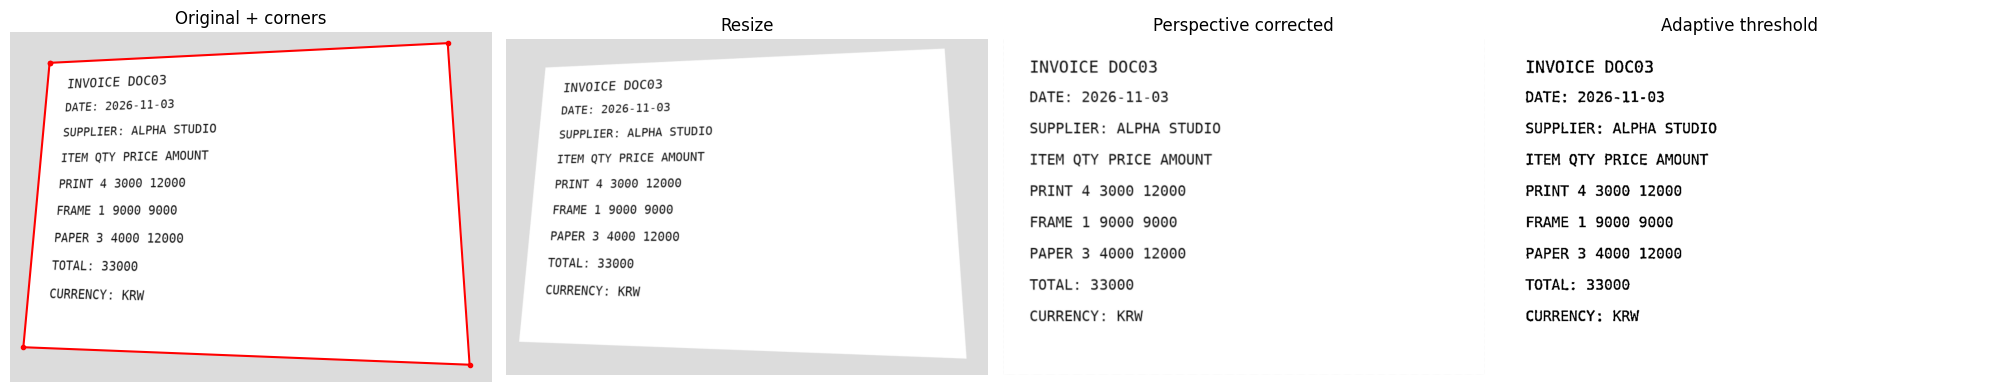

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, view, title in zip(axes, [image, resized, rectified, adaptive],
                          ["Original + corners", "Resize", "Perspective corrected", "Adaptive threshold"]):
    ax.imshow(cv2.cvtColor(view, cv2.COLOR_BGR2RGB) if view.ndim == 3 else view,
              cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
axes[0].plot(*np.vstack([corners, corners[:1]]).T, "r.-")
fig.tight_layout()
display(fig)
plt.close(fig)

## 4. 모서리 대응과 배열 검증

투시 변환 후 네 모서리가 목표 좌표에 도달하는지 확인합니다. 단순 resize의 모서리 위치도 같은 표에 기록합니다. 영상이 달라졌다는 사실만으로 OCR 성능 개선을 판단하지 않습니다.

In [8]:
mapped = cv2.perspectiveTransform(corners.reshape(1, 4, 2), matrix)[0]
comparison = pd.DataFrame({
    "corner": ["TL", "TR", "BR", "BL"],
    "target_x": destination[:, 0], "target_y": destination[:, 1],
    "mapped_x": mapped[:, 0], "mapped_y": mapped[:, 1],
    "error_px": np.linalg.norm(mapped - destination, axis=1),
})
resize_points = (corners + 0.5) * np.array([size[0] / image.shape[1], size[1] / image.shape[0]]) - 0.5
comparison["resize_x"] = resize_points[:, 0]
comparison["resize_y"] = resize_points[:, 1]
display(comparison)
np.testing.assert_allclose(mapped, destination, atol=1e-3, rtol=0)
assert rectified.shape == (size[1], size[0], 3)
assert adaptive.shape == (size[1], size[0])
assert rectified.dtype == adaptive.dtype == np.uint8
assert set(np.unique(adaptive)).issubset({0, 255})
assert not np.array_equal(resized, rectified)
for filename, expected in [("p01_rectified.png", rectified), ("p01_adaptive.png", adaptive)]:
    path = exercise / "outputs" / filename
    if path.exists():
        loaded = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
        np.testing.assert_array_equal(loaded, expected)
        print("기존 PNG 일치:", filename)
    else:
        print("기존 PNG 없음, 메모리 계산만 검증:", filename)
print("검증 통과: 모서리 대응 · shape · dtype · 이진 값 범위")

,corner,target_x,target_y,mapped_x,mapped_y,error_px,resize_x,resize_y
0,TL,0.0,0.0,0.000000e+00,-1.383704e-14,1.383704e-14,81.772727,61.1875
1,TR,999.0,0.0,9.990000e+02,2.462798e-14,2.462798e-14,909.045455,21.8125
2,BR,999.0,699.0,9.990000e+02,6.990000e+02,0.000000e+00,954.500000,664.9375
3,BL,0.0,699.0,-1.241947e-14,6.990000e+02,1.241947e-14,27.227273,629.9375


기존 PNG 일치: p01_rectified.png
기존 PNG 일치: p01_adaptive.png
검증 통과: 모서리 대응 · shape · dtype · 이진 값 범위


## 5. 해석과 설명 질문

**단순 resize와 원근 보정은 어떻게 다를까요?** resize는 영상 전체의 가로·세로 비율만 조정하므로 문서의 사다리꼴 모양이 남습니다. 원근 보정은 제공한 네 모서리를 직사각형에 대응시켜 문서를 펴 줍니다. 따라서 동일한 `(700,1000,3)` shape만으로 구현의 정확성을 판단할 수 없습니다.

README의 제작 환경 기준 입력 shape는 `(800,1100,3)`, 보정 후 shape는 `(700,1000,3)`입니다. 위 실행 표와 모서리 오차로 현재 결과를 확인합니다. 적응형 이진화의 `31`은 이웃 블록 크기, `11`은 가중 평균에서 빼는 상수입니다. 이 설정이 다른 문서에서도 최적이라고 결론 내릴 수는 없습니다.

이번 검증은 알려진 모서리와 제공 문서의 기하 변환에 한정됩니다. 모서리 자동 검출, 실제 OCR 및 OCR 정확도 비교는 수행하지 않습니다.